In [126]:
import pandas as pd

In [127]:
data = pd.read_csv("C:/Users/DELL/Downloads/Logistic_Regression_Classification_Dataset.csv")
data.head()

,Customer_ID,Age,Annual_Income,Website_Visits,Previous_Purchases,Campaign_Contacted,Subscribed
0,CUST0001,56,42192,6,5,Yes,No
1,CUST0002,46,16062,5,3,Yes,No
2,CUST0003,32,99076,8,2,Yes,No
3,CUST0004,60,104780,5,2,No,Yes
4,CUST0005,25,36689,4,1,No,No


In [128]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Customer_ID         600 non-null    str  
 1   Age                 600 non-null    int64
 2   Annual_Income       600 non-null    int64
 3   Website_Visits      600 non-null    int64
 4   Previous_Purchases  600 non-null    int64
 5   Campaign_Contacted  600 non-null    str  
 6   Subscribed          600 non-null    str  
dtypes: int64(4), str(3)
memory usage: 32.9 KB


In [129]:
data.describe()

,Age,Annual_Income,Website_Visits,Previous_Purchases
count,600.000000,600.000000,600.000000,600.000000
mean,41.883333,82285.850000,4.988333,1.973333
std,13.552214,40237.991626,2.278930,1.331256
min,18.000000,15126.000000,0.000000,0.000000
25%,31.000000,47229.000000,3.000000,1.000000
50%,42.500000,81280.500000,5.000000,2.000000
75%,53.000000,118097.000000,6.000000,3.000000
max,65.000000,149869.000000,12.000000,6.000000


In [130]:
import matplotlib.pyplot as plt

{'whiskers': [<matplotlib.lines.Line2D at 0x21f4b2d5310>,
 'caps': [<matplotlib.lines.Line2D at 0x21f4b2d7890>,
 'boxes': [<matplotlib.lines.Line2D at 0x21f4b2d7ed0>],
 'medians': [<matplotlib.lines.Line2D at 0x21f4b2d7610>],
 'fliers': [<matplotlib.lines.Line2D at 0x21f4b2d74d0>],
 'means': []}

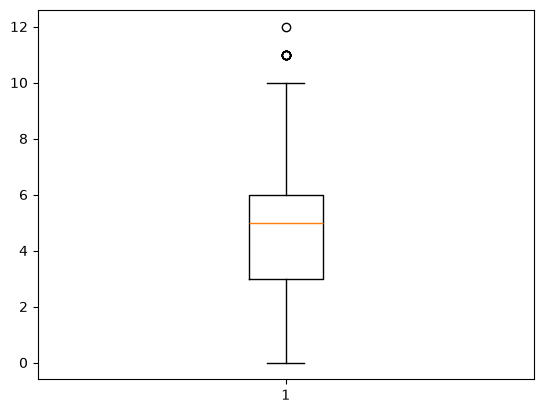

In [131]:
plt.boxplot(data['Website_Visits'])

{'whiskers': [<matplotlib.lines.Line2D at 0x21f4b1307d0>,
 'caps': [<matplotlib.lines.Line2D at 0x21f4b130550>,
 'boxes': [<matplotlib.lines.Line2D at 0x21f4b130190>],
 'medians': [<matplotlib.lines.Line2D at 0x21f4b1302d0>],
 'fliers': [<matplotlib.lines.Line2D at 0x21f4b133750>],
 'means': []}

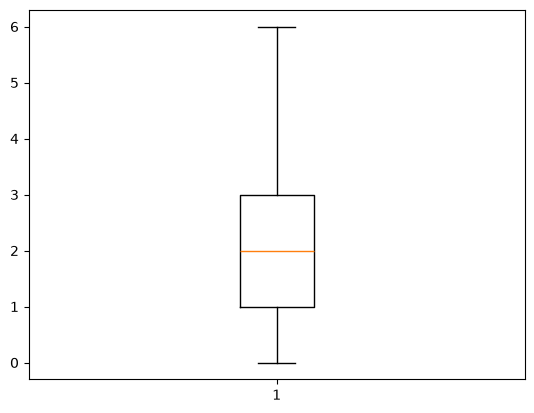

In [132]:
plt.boxplot(data['Previous_Purchases'])

In [133]:
mean = data['Website_Visits'].mean()
std = data['Website_Visits'].std()
ub = mean + 3 * std
lb = mean - 3 * std
ub,lb
data['Website_Visits'] = data['Website_Visits'].astype(float)
data.loc[data['Website_Visits']>ub, 'Website_Visits'] = ub
data.loc[data['Website_Visits']<lb, 'Website_Visits'] = lb

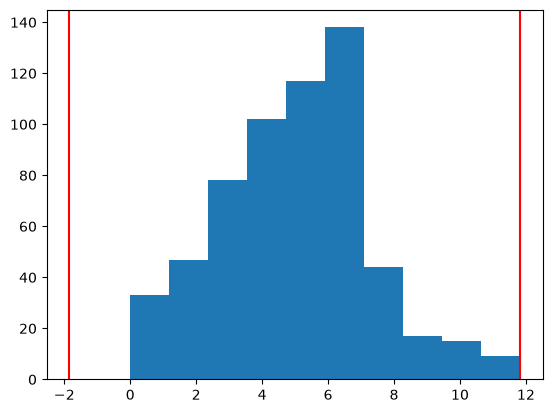

In [134]:
plt.hist(data['Website_Visits'])
plt.axvline(ub, color='red')
plt.axvline(lb, color='red')
plt.show()

In [135]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

data["Campaign_Contacted"] = le.fit_transform( data["Campaign_Contacted"])

In [136]:
data.head()

,Customer_ID,Age,Annual_Income,Website_Visits,Previous_Purchases,Campaign_Contacted,Subscribed
0,CUST0001,56,42192,6.0,5,1,No
1,CUST0002,46,16062,5.0,3,1,No
2,CUST0003,32,99076,8.0,2,1,No
3,CUST0004,60,104780,5.0,2,0,Yes
4,CUST0005,25,36689,4.0,1,0,No


In [137]:
data['Subscribed'].value_counts()

Subscribed
No     321
Yes    279
Name: count, dtype: int64

In [138]:
X = data.drop(['Customer_ID','Subscribed'], axis=1)
y = data['Subscribed']

In [139]:
from imblearn.over_sampling import SMOTE

In [140]:
data['Subscribed'] = data['Subscribed'].replace({'Yes':1,'No':0}).astype('int')
y = data['Subscribed']
y

0      0
1      0
2      0
3      1
4      0
      ..
595    0
596    1
597    0
598    0
599    0
Name: Subscribed, Length: 600, dtype: int64

In [141]:
sm = SMOTE()
X,y = sm.fit_resample(X,y)

In [142]:
y.value_counts()

Subscribed
0    321
1    321
Name: count, dtype: int64

In [143]:
from sklearn.model_selection import train_test_split

In [144]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=18)

In [145]:
from sklearn.linear_model import LogisticRegression

In [146]:
model = LogisticRegression()

In [147]:
model.fit(X_train, y_train)

C:\Users\DELL\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [148]:
train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

In [149]:
from sklearn.metrics import accuracy_score

In [150]:
print('Training Accuracy:', accuracy_score(y_train, train_pred))
print('Testing Accuracy:', accuracy_score(y_test, test_pred))

Training Accuracy: 0.6413255360623782
Testing Accuracy: 0.6511627906976745
